In [1]:
''' This notebook takes all the runs and creates a file with the average of CE_test, CE_train, and accuracy (test),
 called averaged_runs_p_{p}_bs_{bs}.csv, for every pruning percentage and every batch size inside the directories
 (prune_layers_ALL/p-percentage_{p}/batch_size_{bs}/).

 Then, from those files, it creates 6 plots: combined Avg_CE_Train / Avg_CE_Test / Avg_Accuracy vs Batch number
 for each batch size (64, 50000).

 The plots are named as: CE_Train_Avg_SLP_CIFAR10_BS_64.png

 CIFAR-10 version of SLP-FMNIST/02_average_and_plots.ipynb ("Final version color coded").
 Differences: batch sizes 64 and 50000, run files named slp__{p}_{bs}_run_*.txt,
 relative paths, CE axis up to 4.5 (CIFAR-10 test CE goes above ln(10)).
'''

' This notebook takes all the runs and creates a file with the average of CE_test, CE_train, and accuracy (test),\n called averaged_runs_p_{p}_bs_{bs}.csv, for every pruning percentage and every batch size inside the directories\n (prune_layers_ALL/p-percentage_{p}/batch_size_{bs}/).\n\n Then, from those files, it creates 6 plots: combined Avg_CE_Train / Avg_CE_Test / Avg_Accuracy vs Batch number\n for each batch size (64, 50000).\n\n The plots are named as: CE_Train_Avg_SLP_CIFAR10_BS_64.png\n\n CIFAR-10 version of SLP-FMNIST/02_average_and_plots.ipynb ("Final version color coded").\n Differences: batch sizes 64 and 50000, run files named slp__{p}_{bs}_run_*.txt,\n relative paths, CE axis up to 4.5 (CIFAR-10 test CE goes above ln(10)).\n'

Found 11 pruning percentages:
  [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


Processing batch size: 64
  Loading P%=0.0 (100 runs)...


    → Saved: averaged_runs_p_0.0_bs_64.csv
  Loading P%=10.0 (100 runs)...


    → Saved: averaged_runs_p_0.1_bs_64.csv
  Loading P%=20.0 (100 runs)...


    → Saved: averaged_runs_p_0.2_bs_64.csv
  Loading P%=30.0 (100 runs)...


    → Saved: averaged_runs_p_0.3_bs_64.csv
  Loading P%=40.0 (100 runs)...


...

    → Saved: averaged_runs_p_0.7_bs_64.csv
  Loading P%=80.0 (100 runs)...


    → Saved: averaged_runs_p_0.8_bs_64.csv
  Loading P%=90.0 (100 runs)...


    → Saved: averaged_runs_p_0.9_bs_64.csv
  Loading P%=100.0 (100 runs)...


    → Saved: averaged_runs_p_1.0_bs_64.csv

  Creating CE_Train plot...


    → Saved: CE_Train_Avg_SLP_CIFAR10_BS_64.png


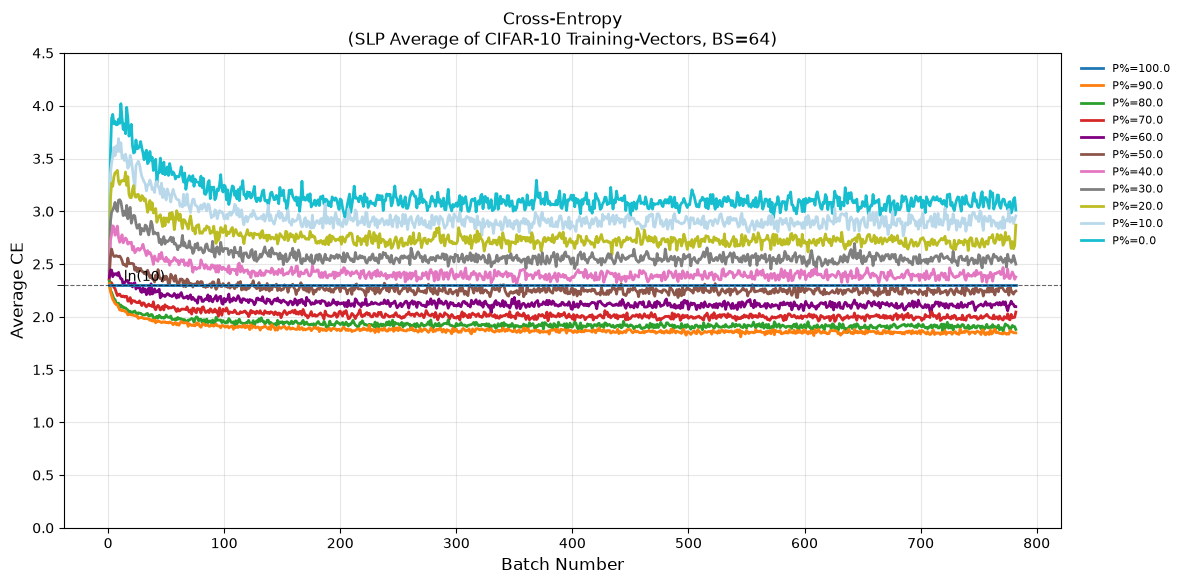

  Creating CE_Test plot...


    → Saved: CE_Test_Avg_SLP_CIFAR10_BS_64.png


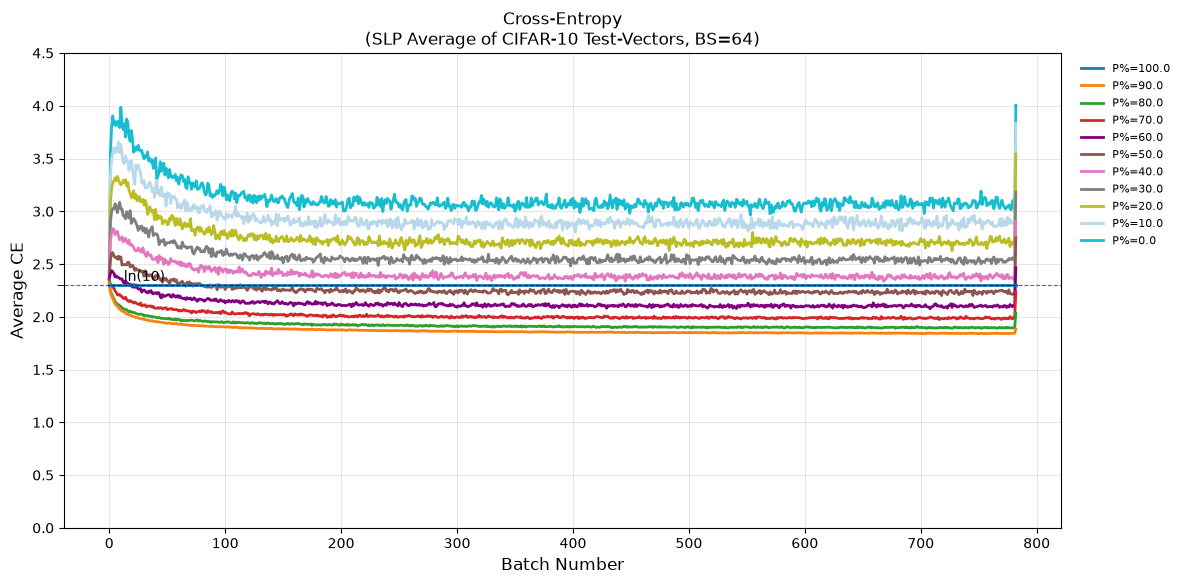

  Creating Accuracy plot...


    → Saved: Accuracy_Avg_SLP_CIFAR10_BS_64.png


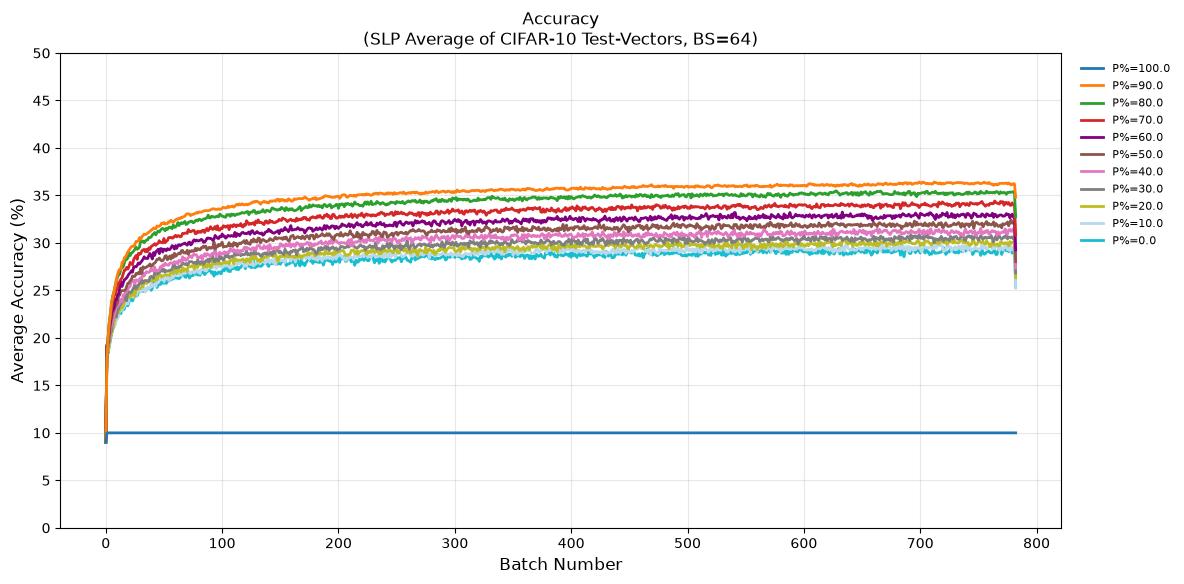


Processing batch size: 50000
  Loading P%=0.0 (100 runs)...


    → Saved: averaged_runs_p_0.0_bs_50000.csv
  Loading P%=10.0 (100 runs)...
    → Saved: averaged_runs_p_0.1_bs_50000.csv
  Loading P%=20.0 (100 runs)...


    → Saved: averaged_runs_p_0.2_bs_50000.csv
  Loading P%=30.0 (100 runs)...
    → Saved: averaged_runs_p_0.3_bs_50000.csv
  Loading P%=40.0 (100 runs)...


    → Saved: averaged_runs_p_0.4_bs_50000.csv
  Loading P%=50.0 (100 runs)...
    → Saved: averaged_runs_p_0.5_bs_50000.csv
  Loading P%=60.0 (100 runs)...


    → Saved: averaged_runs_p_0.6_bs_50000.csv
  Loading P%=70.0 (100 runs)...
    → Saved: averaged_runs_p_0.7_bs_50000.csv
  Loading P%=80.0 (100 runs)...


    → Saved: averaged_runs_p_0.8_bs_50000.csv
  Loading P%=90.0 (100 runs)...
    → Saved: averaged_runs_p_0.9_bs_50000.csv
  Loading P%=100.0 (100 runs)...


    → Saved: averaged_runs_p_1.0_bs_50000.csv

  Creating CE_Train plot...


    → Saved: CE_Train_Avg_SLP_CIFAR10_BS_50000.png


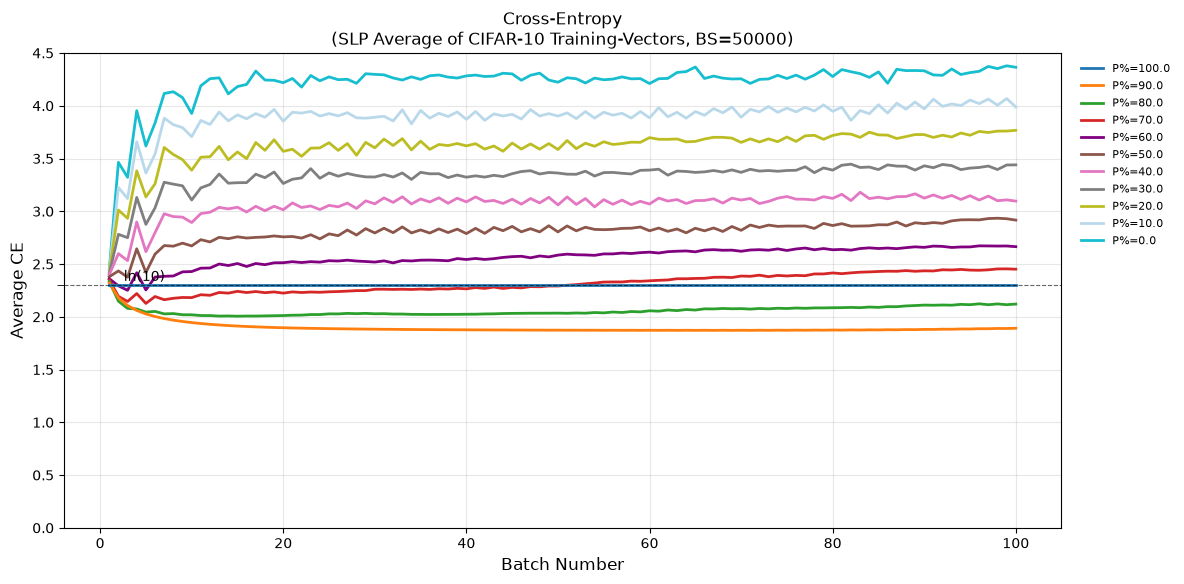

  Creating CE_Test plot...


    → Saved: CE_Test_Avg_SLP_CIFAR10_BS_50000.png


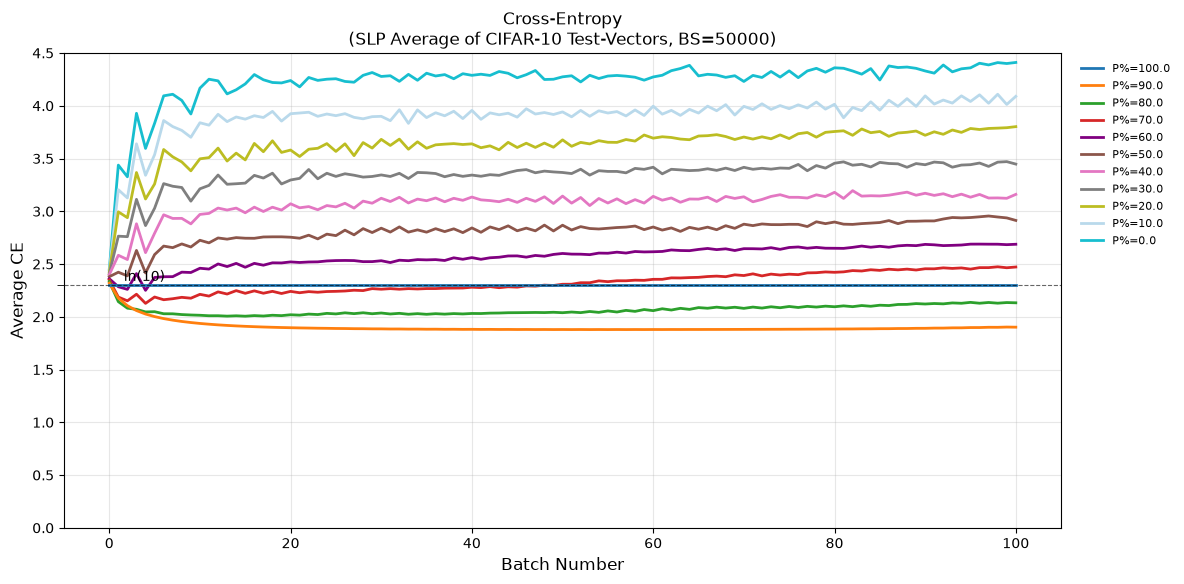

  Creating Accuracy plot...


    → Saved: Accuracy_Avg_SLP_CIFAR10_BS_50000.png


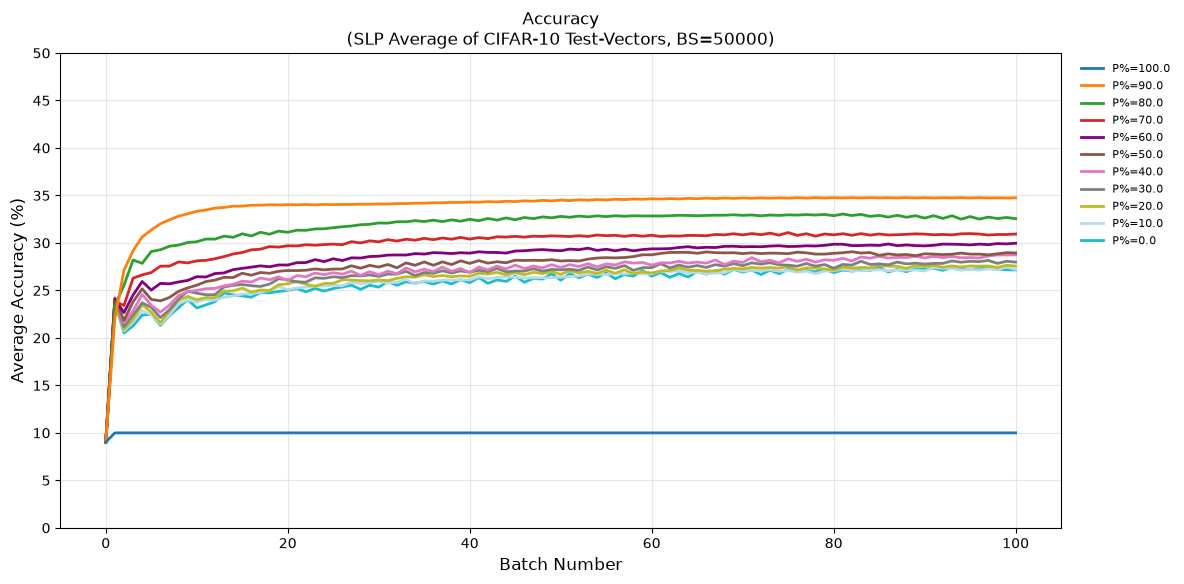


✓ All plots completed successfully!


In [2]:
import pandas as pd
import glob
import os
import numpy as np
import matplotlib.pyplot as plt
import re

# =========================
# CONFIGURATION
# =========================
# Paths are relative to this notebook: SLP-CIFAR10/
BASE_DIR = os.path.abspath("prune_layers_ALL")
OUT_DIR = os.path.abspath(".")
BATCH_SIZES = [64, 50000]
FILE_PATTERN = "slp__{p}_{bs}_run_*.txt"   # CIFAR-10 run files have a double underscore
LN10 = np.log(10)

# =========================
# DYNAMICALLY DETECT ALL PRUNING PERCENTAGES
# =========================
p_dirs = glob.glob(os.path.join(BASE_DIR, "p-percentage_*"))
PRUNING_PERCENTAGES = sorted([
    float(re.search(r"p-percentage_([\d.]+)", d).group(1))
    for d in p_dirs
])

print(f"Found {len(PRUNING_PERCENTAGES)} pruning percentages:")
print(f"  {PRUNING_PERCENTAGES}\n")

# =========================
# COLOR SCHEME FOR PRUNING PERCENTAGES
# =========================
COLOR_LIST_EXTENDED = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#800080",
    "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#B9D9EB", "#17becf",
    "#C5B0D5", "#FDB462", "#80B1D3", "#FB8072", "#BEBADA",
    "#8DD3C7", "#FFFFB3", "#A6D854", "#FB8072", "#FCCDE5"
]
COLOR_LIST = (COLOR_LIST_EXTENDED * ((len(PRUNING_PERCENTAGES) // len(COLOR_LIST_EXTENDED)) + 1))[:len(PRUNING_PERCENTAGES)]
COLOR_LIST = COLOR_LIST[::-1]

# =========================
# MATPLOTLIB STYLING (REDUCED FONT SIZES)
# =========================
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9
})

# CIFAR-10 test CE rises above ln(10) at low pruning (up to ~4.4), so the CE axis
# goes to 4.5 instead of 2.5; accuracy stays below 40%, so that axis stops at 50.
CE_YLIM = (0, 4.5)
CE_YTICKS = [x * 0.5 for x in range(0, 10)]
ACC_YLIM = (0, 50)
ACC_YTICKS = range(0, 51, 5)


def ce_plot(all_avg_dfs, col, vectors, fname, bs):
    plt.figure(figsize=(12, 6))
    for idx, (p, avg_df) in enumerate(all_avg_dfs.items()):
        color = COLOR_LIST[idx % len(COLOR_LIST)]
        plt.plot(avg_df["Batch_Number"], avg_df[col],
                 label=f"P%={p*100:.1f}", color=color, linewidth=2)

    plt.xlabel("Batch Number", fontsize=12)
    plt.ylabel("Average CE", fontsize=12)
    plt.ylim(*CE_YLIM)
    plt.yticks(CE_YTICKS, fontsize=10)
    plt.axhline(LN10, color="k", lw=0.8, ls="--", alpha=0.6)
    plt.text(0.06, LN10 + 0.07, r"$\ln(10)$", transform=plt.gca().get_yaxis_transform(),
             fontsize=10, va="center", ha="left")
    plt.gca().yaxis.set_minor_locator(plt.FixedLocator([LN10]))
    plt.tick_params(axis='y', which='minor', length=5, color='black')
    # title above the axes: inside the axes it would sit on the P=0% curve
    plt.title(f"Cross-Entropy\n(SLP Average of CIFAR-10 {vectors}-Vectors, BS={bs})", fontsize=12)
    handles, labels = plt.gca().get_legend_handles_labels()
    # legend outside the axes: the CIFAR curves fill the upper right corner
    plt.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.01, 1.0),
               frameon=False, ncol=1, fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, fname), bbox_inches="tight", dpi=300)
    print(f"    → Saved: {fname}")
    plt.show()


# =========================
# MAIN LOOP: PROCESS EACH BATCH SIZE
# =========================
for bs in BATCH_SIZES:
    print(f"\n{'='*50}")
    print(f"Processing batch size: {bs}")
    print(f"{'='*50}")

    all_avg_dfs = {}

    # STEP 1: Load and average all runs
    for idx, p in enumerate(PRUNING_PERCENTAGES):
        # Use actual pruning percentage value directly (no reformatting!)
        folder = os.path.join(BASE_DIR, f"p-percentage_{p}", f"batch_size_{bs}")
        files = glob.glob(os.path.join(folder, FILE_PATTERN.format(p=p, bs=bs)))

        if not files:
            print(f"  [WARNING] No files found for P%={p*100:.1f}, BS={bs}")
            continue

        print(f"  Loading P%={p*100:.1f} ({len(files)} runs)...")

        dfs = []
        skipped = 0
        for f in files:
            try:
                # Check if file is empty first
                if os.path.getsize(f) == 0:
                    skipped += 1
                    continue

                df = pd.read_csv(f, sep=r"\s+")
                df.columns = df.columns.str.strip()
                df["CE_Train"] = pd.to_numeric(df["CE_Train"], errors="coerce")
                df["CE_TEST"] = pd.to_numeric(df["CE_TEST"], errors="coerce")
                df["Accuracy(%)"] = pd.to_numeric(df["Accuracy(%)"], errors="coerce")
                dfs.append(df)
            except (pd.errors.EmptyDataError, pd.errors.ParserError) as e:
                skipped += 1
                continue

        if skipped > 0:
            print(f"    ⚠ Skipped {skipped} empty/corrupted files")

        if not dfs:
            print(f"  [ERROR] No valid data found for P%={p*100:.1f}, BS={bs}")
            continue

        all_runs = pd.concat(dfs, ignore_index=True)

        # STEP 2: Compute average by batch number
        avg_df = all_runs.groupby("Batch_Number", as_index=False).agg(
            Avg_CE_Train=("CE_Train", "mean"),
            Avg_CE_Test=("CE_TEST", "mean"),
            Avg_Accuracy=("Accuracy(%)", "mean"),
            Num_Runs=("CE_TEST", "count")
        )

        # STEP 3: Save averaged CSV
        out_csv = os.path.join(folder, f"averaged_runs_p_{p}_bs_{bs}.csv")
        avg_df.to_csv(out_csv, index=False)
        print(f"    → Saved: {os.path.basename(out_csv)}")

        all_avg_dfs[p] = avg_df

    # STEP 4: Create combined plots
    if not all_avg_dfs:
        print(f"  [SKIP] No data available for batch size {bs}")
        continue

    # Plot 1: CE_Train
    print(f"\n  Creating CE_Train plot...")
    ce_plot(all_avg_dfs, "Avg_CE_Train", "Training", f"CE_Train_Avg_SLP_CIFAR10_BS_{bs}.png", bs)

    # Plot 2: CE_Test
    print(f"  Creating CE_Test plot...")
    ce_plot(all_avg_dfs, "Avg_CE_Test", "Test", f"CE_Test_Avg_SLP_CIFAR10_BS_{bs}.png", bs)

    # Plot 3: Accuracy
    print(f"  Creating Accuracy plot...")
    plt.figure(figsize=(12, 6))
    for idx, (p, avg_df) in enumerate(all_avg_dfs.items()):
        color = COLOR_LIST[idx % len(COLOR_LIST)]
        plt.plot(avg_df["Batch_Number"], avg_df["Avg_Accuracy"],
                 label=f"P%={p*100:.1f}", color=color, linewidth=2)

    plt.xlabel("Batch Number", fontsize=12)
    plt.ylabel("Average Accuracy (%)", fontsize=12)
    plt.ylim(*ACC_YLIM)
    plt.yticks(ACC_YTICKS, fontsize=10)
    plt.title(f"Accuracy\n(SLP Average of CIFAR-10 Test-Vectors, BS={bs})", fontsize=12)
    handles, labels = plt.gca().get_legend_handles_labels()
    plt.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.01, 1.0),
               frameon=False, ncol=1, fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    fname = f"Accuracy_Avg_SLP_CIFAR10_BS_{bs}.png"
    plt.savefig(os.path.join(OUT_DIR, fname), bbox_inches="tight", dpi=300)
    print(f"    → Saved: {fname}")
    plt.show()

print(f"\n{'='*50}")
print("✓ All plots completed successfully!")
print(f"{'='*50}")